# Phần B — Region Growing và SRG

### Bài tập 2 — Cài đặt Region Growing và Seeded Region Growing

- **Created**: 2026-11-11T07:35:41+07:00
- **Last Updated**: 2026-11-14T22:35:44+07:00
- **Author**: Xem [nhóm và phân công](../README.md#nhom-va-phan-cong).
- **Objective**: Tự cài đặt, kiểm chứng và phân tích phần B theo đề bài.

## References & Consumed Artifacts

- [Đề bài gốc](../pdf/Computer_Vision%2045.pdf).
- [Hướng dẫn và hợp đồng hàm](../docs/shared/HUONG_DAN_THUC_HIEN.md).
- [Quy ước notebook](../agents/rules/NOTEBOOK_HEADER_CONVENTION.md).
- [Quy tắc báo cáo](../agents/rules/RESULTS_REPORTING.md).
- [Ảnh phần này](../images/phan_b/), [kết quả xuất](../experiments/results/phan_b/).
- Source Code: bốn hàm phần B và các hàm hỗ trợ được định nghĩa trực tiếp trong notebook; kiểm chứng tổng hợp được chạy trong notebook; thí nghiệm chính và ảnh thật chưa hoàn thành.

Hai notebook là bản làm việc; trước khi nộp phải ghép thành một notebook theo đề.


## 1. Thư viện và quy ước cài đặt

Các hàm được cài đặt trực tiếp trong notebook. Không gọi hàm góc /
phân vùng dựng sẵn bên trong hàm phải nộp. Đối chiếu thư viện chỉ ở phần được đề cho phép.

Được dùng NumPy, Matplotlib, math, time; heapq cho SRG. Các hàm SciPy/OpenCV có điều kiện
phải đối chiếu bảng thư viện ở README và đề. Cài thư viện không đồng nghĩa được dùng mọi hàm.

Nhóm tự chọn ảnh, giả thuyết, phép đo, tham số và kết luận.

## 2. Môi trường và dữ liệu — nhóm tự điền

Metadata kernel là Python 3; phiên bản trong metadata phản ánh môi trường lúc dựng khung,
không thay thế việc ghi phiên bản thực tế khi chạy bài.

| Thành phần | Phiên bản / thông tin thực tế |
| --- | --- |
| Python / đường dẫn kernel | 3.12.6; `D:\Download\Computer-Vision_Lab2\.venv\Scripts\python.exe` |
| NumPy / Matplotlib / OpenCV | 2.5.4 / 3.11.2 / 5.0.0 |
| Thiết bị, thời điểm chạy, seed ngẫu nhiên | Windows-11-10.0.26200-SP0; 2026-11-14T22:32:12+07:00; RNG seed 42 |

| Ảnh | Nguồn / quyền sử dụng | Kích thước / kiểu / miền cường độ | Phép chỉnh sửa |
| --- | --- | --- | --- |
| [Ảnh phẳng](../images/phan_b/anh_phang.png) | Tự tổng hợp bằng code NumPy trong notebook, hỗ trợ AI được khai báo tại cell tạo ảnh | 64×64; uint8; giá trị 128 | Không |
| [Gradient ngang](../images/phan_b/gradient_ngang.png) | Tự tổng hợp bằng code NumPy trong notebook, hỗ trợ AI được khai báo tại cell tạo ảnh | 128×128; uint8; [0,255] | Không |
| [Hai vùng có cầu nối](../images/phan_b/hai_vung_cau_noi.png) | Tự tổng hợp bằng code NumPy trong notebook, hỗ trợ AI được khai báo tại cell tạo ảnh | 128×128; uint8; [20,160] | Không |

- Mở notebook với working directory là thư mục chứa notebook.
- Đọc ảnh từ `../images/phan_b/`; xuất bảng/hình vào `../experiments/results/phan_b/`.
- Ghi rõ ảnh xám `(H, W)`, miền cường độ và ngưỡng cùng đơn vị.
- Điểm theo `(row, col)`; khi vẽ trục ngang là col, trục dọc là row.
- Quy ước biên, seeds, biến đổi và ghép/đếm: nhóm tự ghi trước khi đo.

Ô dưới chỉ khai báo NumPy, heapq và bộ máy SRG dùng chung. Stack dùng list; queue dùng list kèm chỉ số đọc.

Ảnh float64 giữ nguyên miền cường độ. Seeds là các tọa độ nguyên (row, col), không rỗng, không trùng, nằm trong ảnh; nhãn theo thứ tự seeds. Lân cận 4: trên, trái, phải, dưới; lân cận 8 bổ sung chéo trên trái, trên phải, dưới trái, dưới phải. SRG dùng heap lazy; biên là pixel kề nhiều vùng tại thời điểm gán và vẫn có nhãn. Phá hòa insertion theo thứ tự chèn/seed, raster theo tọa độ pixel/seed, random theo ưu tiên cố định trong mỗi lần chạy. Đặt np.random.seed trước khi chạy để tái lập. Các quy ước frames và sensitivity được ghi trong docstring.


In [1]:
import heapq
import numpy as np


def _b_integer(value, name, minimum=0):
    if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)) or value < minimum:
        raise ValueError(f"{name} phải là số nguyên >= {minimum}")
    return int(value)


def _b_inputs(img, seeds):
    image = np.asarray(img, dtype=np.float64)
    if image.ndim != 2 or image.size == 0 or not np.isfinite(image).all():
        raise ValueError("img phải là ảnh xám 2D hữu hạn, không rỗng")
    points = np.asarray(seeds)
    if (points.ndim != 2 or points.shape[1] != 2 or len(points) == 0
            or not np.issubdtype(points.dtype, np.integer)
            or np.any(points < 0) or np.any(points >= image.shape)):
        raise ValueError("seeds phải là mảng tọa độ nguyên (N, 2) nằm trong ảnh")
    if len(np.unique(points, axis=0)) != len(points):
        raise ValueError("seeds không được trùng vị trí")
    return image, points.astype(np.intp, copy=True)


def _b_neighbors(row, col, shape, connectivity=4):
    offsets = [(-1, 0), (0, -1), (0, 1), (1, 0)]
    if connectivity == 8:
        offsets += [(-1, -1), (-1, 1), (1, -1), (1, 1)]
    for dr, dc in offsets:
        r, c = row + dr, col + dc
        if 0 <= r < shape[0] and 0 <= c < shape[1]:
            yield r, c


def _b_srg_engine(img, seeds, connectivity=4, stale="lazy", tie="insertion", on_step=None):
    image, seeds = _b_inputs(img, seeds)
    if connectivity not in (4, 8):
        raise ValueError("connectivity phải là 4 hoặc 8")
    if stale not in ("lazy", "frozen"):
        raise ValueError("stale phải là lazy hoặc frozen")
    if tie not in ("insertion", "raster", "random"):
        raise ValueError("tie phải là insertion, raster hoặc random")
    labels = np.full(image.shape, -1, dtype=np.int32)
    boundary = np.zeros(image.shape, dtype=bool)
    for region, (row, col) in enumerate(seeds):
        labels[row, col] = region
    totals = image[seeds[:, 0], seeds[:, 1]].copy()
    seed_values = totals.copy()
    counts = np.ones(len(seeds), dtype=np.int64)
    versions = np.zeros(image.shape, dtype=np.int64)
    insertion = np.full(image.shape, -1, dtype=np.int64)
    serial = 0
    heap = []
    if tie == "random":
        pixel_priority = np.random.random(image.shape)
        region_priority = np.random.random(len(seeds))

    def best_region(row, col):
        adjacent = sorted({int(labels[r, c]) for r, c in
                           _b_neighbors(row, col, image.shape, connectivity) if labels[r, c] >= 0})
        if not adjacent:
            raise RuntimeError("Pixel frontier không kề vùng nào")
        def key(region):
            reference = totals[region] / counts[region] if stale == "lazy" else seed_values[region]
            delta = abs(float(image[row, col] - reference))
            if tie == "raster":
                priority = tuple(seeds[region])
            elif tie == "random":
                priority = (float(region_priority[region]),)
            else:
                priority = (region,)
            return (delta, *priority, region)
        winner = min(adjacent, key=key)
        return key(winner)[0], winner, len(adjacent) > 1

    def enqueue(row, col):
        nonlocal serial
        if labels[row, col] >= 0:
            return
        if insertion[row, col] < 0:
            insertion[row, col] = serial
            serial += 1
        delta, region, _ = best_region(row, col)
        versions[row, col] += 1
        if tie == "raster":
            priority = (row, col)
        elif tie == "random":
            priority = (float(pixel_priority[row, col]), int(insertion[row, col]))
        else:
            priority = (int(insertion[row, col]), 0)
        heapq.heappush(heap, (delta, *priority, row, col, int(versions[row, col]), region))

    for row, col in seeds:
        for r, c in _b_neighbors(row, col, image.shape, connectivity):
            enqueue(r, c)
    assigned = len(seeds)
    if on_step is not None:
        on_step(labels, assigned)
    while heap:
        saved_delta, _, _, row, col, version, saved_region = heapq.heappop(heap)
        if labels[row, col] >= 0 or version != versions[row, col]:
            continue
        delta, region, is_boundary = best_region(row, col)
        if delta != saved_delta or region != saved_region:
            enqueue(row, col)
            continue
        labels[row, col] = region
        boundary[row, col] = is_boundary
        totals[region] += image[row, col]
        counts[region] += 1
        assigned += 1
        if on_step is not None:
            on_step(labels, assigned)
        for r, c in _b_neighbors(row, col, image.shape, connectivity):
            enqueue(r, c)
    return labels, boundary


## 3. Region Growing — tự cài đặt

Các hàm được định nghĩa trong các ô code dưới đây.

### `region_growing_classic(img, seeds, T, order="stack")`

**Hợp đồng đầu ra:** Mảng nhãn int32; -1 cho pixel chưa thuộc vùng; hỗ trợ stack (LIFO) và queue (FIFO).

**Trạng thái:** Đã cài đặt trong ô code tiếp theo; chưa chạy thí nghiệm trên ảnh tự chọn.

In [2]:
def region_growing_classic(img, seeds, T, order="stack"):
    """Phát triển từng vùng, lân cận 4; ngưỡng so với trung bình cập nhật.

    Khởi tạo tất cả seed trước, xử lý vùng theo thứ tự seeds. Frontier
    chứa pixel đã nhận: duyệt lân cận, xét ngưỡng và cập nhật trung bình
    ngay trước khi đưa pixel lân cận được nhận vào stack/queue (PDF trang 6).
    """
    image, seeds = _b_inputs(img, seeds)
    if not np.isfinite(T) or T < 0:
        raise ValueError("T phải không âm và hữu hạn")
    if order not in ("stack", "queue"):
        raise ValueError("order phải là stack hoặc queue")
    labels = np.full(image.shape, -1, dtype=np.int32)
    for region, (row, col) in enumerate(seeds):
        labels[row, col] = region
    for region, (row, col) in enumerate(seeds):
        total, count = float(image[row, col]), 1
        frontier = [(row, col)]
        head = 0
        while frontier if order == "stack" else head < len(frontier):
            if order == "stack":
                r, c = frontier.pop()
            else:
                r, c = frontier[head]
                head += 1
            for nr, nc in _b_neighbors(r, c, image.shape):
                if labels[nr, nc] < 0 and abs(float(image[nr, nc]) - total / count) <= T:
                    labels[nr, nc] = region
                    total += image[nr, nc]
                    count += 1
                    frontier.append((nr, nc))
    return labels


## 4. SRG và hàm hỗ trợ — tự cài đặt

Các hàm được định nghĩa trong các ô code dưới đây.

### `srg(img, seeds, connectivity=4, stale="lazy", tie="insertion")`

**Hợp đồng đầu ra:** (labels, boundary_mask); nhãn cuối cùng đều ≥ 0; dùng heapq; các lựa chọn stale/tie theo đề.

**Trạng thái:** Đã cài đặt trong ô code tiếp theo; chưa chạy thí nghiệm trên ảnh tự chọn.

In [3]:
def srg(img, seeds, connectivity=4, stale="lazy", tie="insertion"):
    """Trả (labels int32, boundary_mask bool), mọi pixel cuối cùng có nhãn.

    lazy: tính lại delta khi pop theo trung bình vùng hiện tại, requeue nếu
    thay đổi. frozen: so với cường độ seed. Heap lazy không quét lại toàn
    bộ frontier khi trung bình đổi; ưu tiên là các khóa hiện có trong heap.
    boundary_mask ghi pixel kề nhiều vùng tại thời điểm gán, không gồm seed.
    random dùng np.random.seed để tái lập; ưu tiên ngẫu nhiên cố định trong lần chạy.
    """
    return _b_srg_engine(img, seeds, connectivity, stale, tie)


### `srg_step_frames(img, seeds, n_frames=8, **kwargs)`

**Hợp đồng đầu ra:** Danh sách n_frames ảnh nhãn tại các mốc tiến trình; các ảnh là bản chụp độc lập.

**Trạng thái:** Đã cài đặt trong ô code tiếp theo; chưa chạy thí nghiệm trên ảnh tự chọn.

In [4]:
def srg_step_frames(img, seeds, n_frames=8, **kwargs):
    """Chụp tại ceil(k * số_pixel / n_frames), k=1..n_frames; frame cuối hoàn tất.

    n_frames=1 chỉ chụp kết quả cuối. Nhiều mốc trùng nhau trên ảnh nhỏ
    hoặc mốc đã đạt ngay khi gán seeds vẫn tạo các bản sao độc lập.
    kwargs hỗ trợ connectivity, stale và tie.
    """
    image, seeds = _b_inputs(img, seeds)
    n_frames = _b_integer(n_frames, "n_frames", 1)
    targets = np.ceil(np.arange(1, n_frames + 1) * image.size / n_frames).astype(int)
    frames = []
    def capture(labels, assigned):
        while len(frames) < n_frames and assigned >= targets[len(frames)]:
            frames.append(labels.copy())
    _b_srg_engine(image, seeds, on_step=capture, **kwargs)
    return frames


### `seed_sensitivity(img, seeds, segment_fn, n_trials=20, jitter=3)`

**Hợp đồng đầu ra:** Bản đồ tần suất đổi nhãn khi dịch seeds trong khoảng ±jitter; ghi quy ước nhãn và cách xử lý jitter không hợp lệ.

**Trạng thái:** Đã cài đặt trong ô code tiếp theo; chưa chạy thí nghiệm trên ảnh tự chọn.

In [5]:
def seed_sensitivity(img, seeds, segment_fn, n_trials=20, jitter=3):
    """Tần suất đổi vùng theo định danh seed, so với phân vùng gốc.

    segment_fn(image, seeds) trả labels hoặc (labels, boundary_mask).
    Nhãn tại các seed phải khác nhau; pixel chưa gán giữ mã -1. Dịch seed
    trong cửa sổ nguyên ±jitter, giới hạn trong ảnh, không trùng; tránh các
    vị trí seed gốc còn lại để luôn có lựa chọn dự phòng. Dùng np.random.seed
    để tái lập. Mỗi lần gọi segment_fn dùng cùng trạng thái NumPy RNG
    toàn cục rồi khôi phục RNG bên ngoài, tách khỏi randomness dịch seeds.
    Callable dùng RNG riêng phải tự được cấu hình tái lập.
    """
    image, seeds = _b_inputs(img, seeds)
    n_trials = _b_integer(n_trials, "n_trials", 1)
    jitter = _b_integer(jitter, "jitter")
    if not callable(segment_fn):
        raise ValueError("segment_fn phải là callable")
    segmentation_rng_state = np.random.get_state()
    def segment(points):
        outer_rng_state = np.random.get_state()
        try:
            np.random.set_state(segmentation_rng_state)
            output = segment_fn(image.copy(), points.copy())
        finally:
            np.random.set_state(outer_rng_state)
        labels = np.asarray(output[0] if isinstance(output, tuple) else output)
        if (labels.shape != image.shape or not np.issubdtype(labels.dtype, np.integer)
                or np.any(labels < -1)):
            raise ValueError("segment_fn phải trả ảnh nhãn nguyên cùng shape; nhãn >= -1")
        ids = labels[points[:, 0], points[:, 1]]
        if np.any(ids < 0) or len(np.unique(ids)) != len(points):
            raise ValueError("mỗi seed phải thuộc một vùng khác nhau")
        normalized = np.full(image.shape, -1, dtype=np.int32)
        for region, label in enumerate(ids):
            normalized[labels == label] = region
        if np.any((labels >= 0) & (normalized < 0)):
            raise ValueError("vùng có nhãn phải tương ứng với một seed")
        return normalized
    baseline = segment(seeds)
    changed = np.zeros(image.shape, dtype=np.float64)
    for _ in range(n_trials):
        moved = seeds.copy()
        occupied = {tuple(point) for point in seeds}
        for index, (row, col) in enumerate(seeds):
            occupied.remove(tuple(seeds[index]))
            candidates = [(r, c)
                          for r in range(max(0, row - jitter), min(image.shape[0], row + jitter + 1))
                          for c in range(max(0, col - jitter), min(image.shape[1], col + jitter + 1))
                          if (r, c) not in occupied]
            choice = candidates[np.random.randint(len(candidates))] if candidates else (row, col)
            moved[index] = choice
            occupied.add(choice)
        changed += segment(moved) != baseline
    return changed / n_trials


### Dữ liệu tổng hợp cho phần B

Nguồn: ảnh tự tổng hợp bằng code NumPy trong ô bên dưới, có hỗ trợ AI theo prompt đã ghi. Không dùng công cụ sinh ảnh AI; không có nhiễu nên không cần RNG seed khi tạo dữ liệu.

| File trong thư mục ảnh B | Mảng nguồn | Nội dung / mục đích thử |
| --- | --- | --- |
| [anh_phang.png](../images/phan_b/anh_phang.png) | `(64, 64)`, uint8 | Mọi pixel bằng 128; dùng thử phá hòa với hai seeds |
| [gradient_ngang.png](../images/phan_b/gradient_ngang.png) | `(128, 128)`, uint8 | Tăng từ 0 đến 255 theo chiều ngang; dùng thử lazy/frozen |
| [hai_vung_cau_noi.png](../images/phan_b/hai_vung_cau_noi.png) | `(128, 128)`, uint8 | Nền 20; hai hình tròn 100/160 nối bằng cầu gradient; dùng thử quét T |

Hai hình tròn có tâm `(64, 36)` và `(64, 92)`, bán kính 20. Cầu nằm tại hàng 60–68, cột 54–74, tăng từ 100 đến 160. Mọi tọa độ theo `(row, col)`.

Matplotlib lưu PNG hiển thị xám, có thể chứa các kênh RGB/alpha. Khi phân vùng, dùng trực tiếp các mảng xám uint8 trong `b_images` (các hàm sẽ chuyển sang float64 và giữ miền cường độ); khi đọc PNG lại, chuyển về ảnh xám trước khi truyền vào thuật toán. Các kiểm chứng chạy ở mục 5; thí nghiệm chính và kết luận ảnh thật chưa hoàn thành.

**Khai báo AI — chỉ tạo dữ liệu tổng hợp và hiển thị/lưu ảnh.**

Prompt nguyên văn:

> tạo ảnh thử đi xong tự ném prompt ở trước cell, lưu ảnh vô image B nha

Đã lưu ..\images\phan_b\anh_phang.png: (64, 64), uint8, [128, 128]
Đã lưu ..\images\phan_b\gradient_ngang.png: (128, 128), uint8, [0, 255]
Đã lưu ..\images\phan_b\hai_vung_cau_noi.png: (128, 128), uint8, [20, 160]


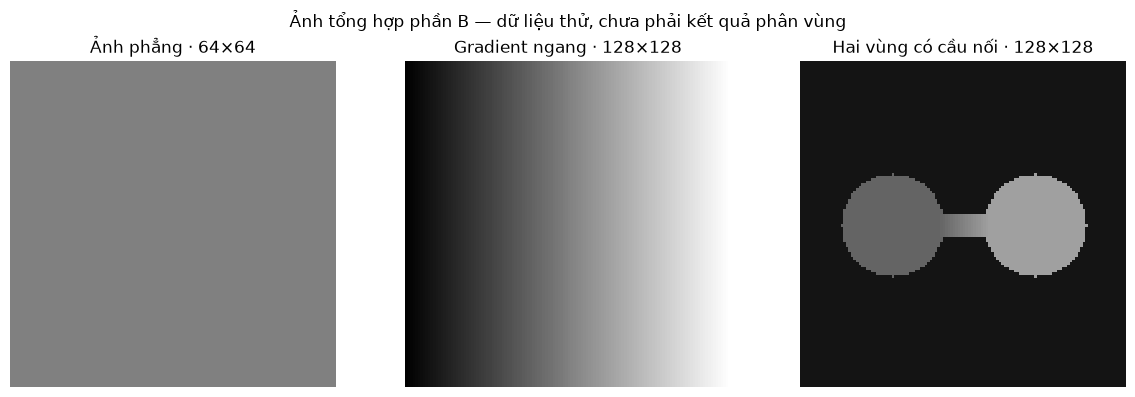

In [6]:
from pathlib import Path
import matplotlib.pyplot as plt

# Working directory là thư mục chứa notebook.
b_image_dir = Path("../images/phan_b")
b_image_dir.mkdir(parents=True, exist_ok=True)

b_flat = np.full((64, 64), 128, dtype=np.uint8)
b_gradient = np.tile(np.rint(np.linspace(0, 255, 128)).astype(np.uint8), (128, 1))

b_rows, b_cols = np.indices((128, 128))
b_bridge = np.full((128, 128), 20, dtype=np.uint8)
b_left = (b_rows - 64) ** 2 + (b_cols - 36) ** 2 <= 20 ** 2
b_right = (b_rows - 64) ** 2 + (b_cols - 92) ** 2 <= 20 ** 2
b_bridge[b_left] = 100
b_bridge[b_right] = 160
b_bridge[60:69, 54:75] = np.rint(np.linspace(100, 160, 21)).astype(np.uint8)[None, :]

b_images = {
    "anh_phang": b_flat,
    "gradient_ngang": b_gradient,
    "hai_vung_cau_noi": b_bridge,
}
assert b_flat.shape == (64, 64) and np.all(b_flat == 128)
assert b_gradient.shape == b_bridge.shape == (128, 128)
assert np.all(b_gradient[:, 0] == 0) and np.all(b_gradient[:, -1] == 255)
assert np.all(np.diff(b_gradient.astype(int), axis=1) >= 0)
assert b_bridge[0, 0] == 20 and b_bridge[64, 36] == 100 and b_bridge[64, 92] == 160
assert b_bridge[64, 54] == 100 and b_bridge[64, 74] == 160
assert np.all(np.diff(b_bridge[64, 54:75].astype(int)) >= 0)

for b_name, b_image in b_images.items():
    assert b_image.ndim == 2 and b_image.dtype == np.uint8
    assert 0 <= int(b_image.min()) <= int(b_image.max()) <= 255
    b_path = b_image_dir / (b_name + ".png")
    # RGB uint8 bằng nhau để tránh làm tròn cường độ qua bảng màu.
    plt.imsave(b_path, np.repeat(b_image[..., None], 3, axis=2))
    # Xác nhận PNG lưu đủ kích thước và giữ đúng cường độ ảnh nguồn.
    b_saved = plt.imread(b_path)
    b_gray = b_saved if b_saved.ndim == 2 else b_saved[..., 0]
    assert b_gray.shape == b_image.shape
    assert np.array_equal(np.rint(b_gray * 255).astype(np.uint8), b_image)
    print(f"Đã lưu {b_path}: {b_image.shape}, uint8, [{b_image.min()}, {b_image.max()}]")

b_titles = ["Ảnh phẳng · 64×64", "Gradient ngang · 128×128", "Hai vùng có cầu nối · 128×128"]
b_figure, b_axes = plt.subplots(1, 3, figsize=(12, 4))
for b_axis, b_image, b_title in zip(b_axes, b_images.values(), b_titles):
    b_axis.imshow(b_image, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    b_axis.set_title(b_title)
    b_axis.set_axis_off()
b_figure.suptitle("Ảnh tổng hợp phần B — dữ liệu thử, chưa phải kết quả phân vùng")
b_figure.tight_layout()
plt.show()


## 5. Kiểm chứng phần B

Các cell dưới dùng ba ảnh tổng hợp tại mục dữ liệu. Cấu hình, thời điểm, môi trường và seeds được ghi vào CSV; người thực hiện theo README. Nhãn được căn chỉnh theo seed trước khi đếm pixel khác. Các bảng là số đo thật từ lần Run All, không phải số minh họa.


**Khai báo AI — cấu hình kiểm chứng, hàm hiển thị và lưu kết quả.**

Prompt nguyên văn:

> chạy kiểm thử đi với thêm cell để chuẩn bị chạy ảnh thật (2 ảnh)

In [7]:
import csv
import platform
import sys
from datetime import datetime
import cv2

b_result_dir = Path("../experiments/results/phan_b/synthetic")
b_result_dir.mkdir(parents=True, exist_ok=True)
b_run_stamp = datetime.now().astimezone().isoformat(timespec="seconds")
b_rng_seed = 42
b_test_T = 30.0
b_test_seeds = {
    "anh_phang": np.array([(16, 16), (48, 48)]),
    "gradient_ngang": np.array([(64, 8), (64, 80)]),
    "hai_vung_cau_noi": np.array([(10, 10), (64, 36), (64, 92)]),
}


def b_write_table(path, columns, rows):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", encoding="utf-8-sig", newline="") as stream:
        writer = csv.writer(stream)
        writer.writerow(columns)
        writer.writerows(rows)
    text_rows = [[str(value) for value in row] for row in [columns, *rows]]
    widths = [max(len(row[i]) for row in text_rows) for i in range(len(columns))]
    for row in text_rows:
        print(" | ".join(value.ljust(width) for value, width in zip(row, widths)))
    print(f"Đã lưu: {path}\n")


def b_save_figure(figure, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    figure.tight_layout(rect=(0, 0, 1, 0.88), h_pad=3.0)
    figure.savefig(path, dpi=140, bbox_inches="tight")
    plt.show()
    plt.close(figure)


def b_show_labels(axis, labels, seeds, title):
    colors = plt.get_cmap("tab20", len(seeds)).copy()
    colors.set_bad("#888888")
    axis.imshow(np.ma.masked_less(labels, 0), cmap=colors,
                vmin=0, vmax=max(1, len(seeds) - 1), interpolation="nearest")
    seeds = np.asarray(seeds)
    axis.scatter(seeds[:, 1], seeds[:, 0], marker="x", c="red", s=35)
    for index, (row, col) in enumerate(seeds):
        axis.text(col + 2, row, str(index), color="red", fontsize=8)
    axis.set_title(title)
    axis.set_axis_off()


def b_align_labels(labels, original_seeds):
    seeds = np.asarray(original_seeds, dtype=int)
    ids = labels[seeds[:, 0], seeds[:, 1]]
    assert np.all(ids >= 0) and len(np.unique(ids)) == len(seeds)
    aligned = np.full(labels.shape, -1, dtype=np.int32)
    for canonical, label in enumerate(ids):
        aligned[labels == label] = canonical
    assert not np.any((labels >= 0) & (aligned < 0))
    return aligned


def b_compare_methods(image, seeds, T, output_dir, name, srg_labels=None):
    image, seeds = _b_inputs(image, seeds)
    if srg_labels is None:
        np.random.seed(b_rng_seed)
        srg_labels = srg(image, seeds, connectivity=4, stale="lazy", tie="insertion")[0]
    labels = {
        "stack": region_growing_classic(image, seeds, T, "stack"),
        "queue": region_growing_classic(image, seeds, T, "queue"),
        "srg": srg_labels,
    }
    labels = {method: b_align_labels(value, seeds) for method, value in labels.items()}
    figure, axes = plt.subplots(1, 3, figsize=(12, 4))
    metrics = []
    for axis, (method, value) in zip(axes, labels.items()):
        b_show_labels(axis, value, seeds, f"{method} · chưa gán: {(value < 0).sum()}")
        metrics.append([name, method, T if method != "srg" else "không dùng T",
                        int((value < 0).sum()), float(np.mean(value >= 0)), len(seeds)])
    figure.suptitle(f"{name} · T={T:g}, 4-neighbor; SRG lazy/insertion\nMàu xám: pixel chưa gán; dấu x: seed")
    b_save_figure(figure, Path(output_dir) / f"{name}_methods.png")
    pairs = []
    for first, second in [("stack", "queue"), ("stack", "srg"), ("queue", "srg")]:
        count = int(np.count_nonzero(labels[first] != labels[second]))
        pairs.append([name, first, second, count, image.size, count / image.size])
    b_write_table(Path(output_dir) / f"{name}_coverage.csv",
                  ["image", "method", "T", "unassigned_pixels", "assigned_fraction", "seeds"], metrics)
    b_write_table(Path(output_dir) / f"{name}_pairwise.csv",
                  ["image", "method_a", "method_b", "different_pixels", "total_pixels", "different_fraction"], pairs)
    return {"labels": labels, "metrics": metrics, "pairwise": pairs}


b_write_table(b_result_dir / "run_metadata.csv", ["field", "value"], [
    ["run_at", b_run_stamp], ["python", sys.version.split()[0]], ["kernel", sys.executable],
    ["numpy", np.__version__], ["matplotlib", plt.matplotlib.__version__],
    ["opencv", cv2.__version__], ["platform", platform.platform()],
    ["rng_seed", b_rng_seed], ["connectivity", 4], ["T_classic", b_test_T],
    ["intensity_range", "0..255"], ["who", "Nhóm theo README; cấu hình và ảnh ghi trong CSV"],
])
b_write_table(b_result_dir / "synthetic_seeds.csv", ["image", "region", "row", "col"],
              [[name, region, int(row), int(col)] for name, seeds in b_test_seeds.items()
               for region, (row, col) in enumerate(seeds)])
b_base = {}
for b_name, b_image in b_images.items():
    np.random.seed(b_rng_seed)
    b_base[b_name] = srg(b_image, b_test_seeds[b_name], connectivity=4, stale="lazy", tie="insertion")
print("Cấu hình và bảng số thuộc lần chạy:", b_run_stamp)


field           | value                                                    
run_at          | 2026-11-14T22:32:12+07:00                                
python          | 3.12.6                                                   
kernel          | D:\Download\Computer-Vision_Lab2\.venv\Scripts\python.exe
numpy           | 2.5.4                                                    
matplotlib      | 3.11.2                                                   
opencv          | 5.0.0                                                    
platform        | Windows-11-10.0.26200-SP0                                
rng_seed        | 42                                                       
connectivity    | 4                                                        
T_classic       | 30.0                                                     
intensity_range | 0..255                                                   
who             | Nhóm theo README; cấu hình và ảnh ghi trong CSV          
Đã lưu: ..\e

Cấu hình và bảng số thuộc lần chạy: 2026-11-14T22:32:12+07:00


### 5.1. Phân hoạch đầy đủ

SRG lazy/insertion, connectivity 4 trên cả ba ảnh; kiểm tra labels int32, mặt nạ biên bool và mọi pixel có nhãn. Lưu hình ảnh/seeds/nhãn, số pixel chưa gán và tỷ lệ gán. [Bảng CSV](../experiments/results/phan_b/synthetic/05_01_partition.csv).


**Khai báo AI — khung chạy kiểm chứng, hiển thị và lưu số đo.**

Prompt nguyên văn:

> chạy kiểm thử đi với thêm cell để chuẩn bị chạy ảnh thật (2 ảnh)

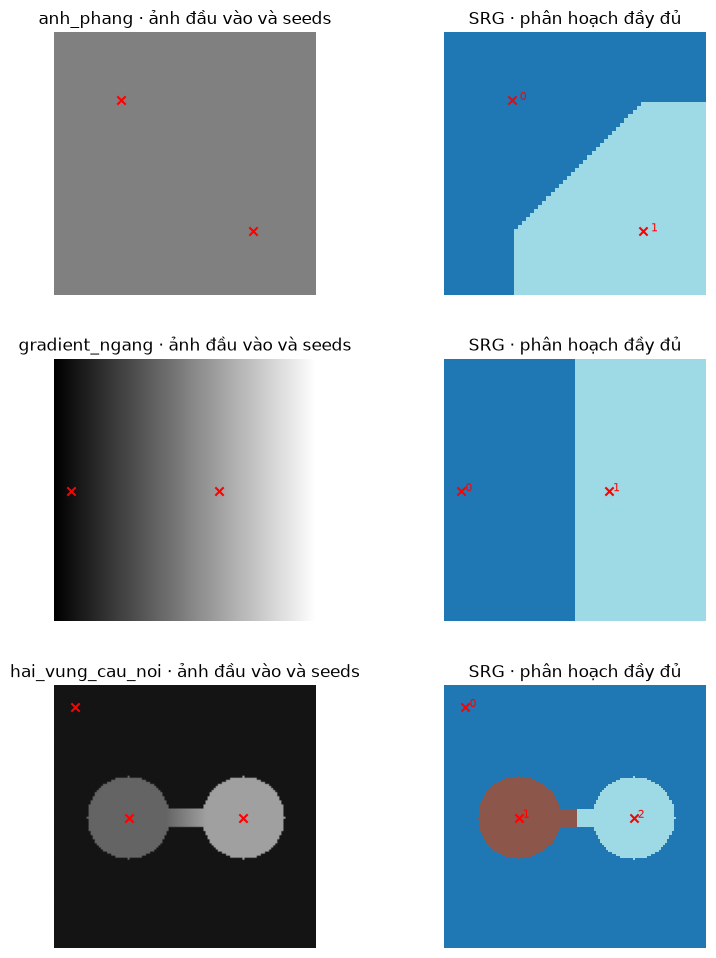

image            | total_pixels | unassigned_pixels | assigned_fraction | status
anh_phang        | 4096         | 0                 | 1.0               | PASS  
gradient_ngang   | 16384        | 0                 | 1.0               | PASS  
hai_vung_cau_noi | 16384        | 0                 | 1.0               | PASS  
Đã lưu: ..\experiments\results\phan_b\synthetic\05_01_partition.csv



In [8]:
b_partition_rows = []
b_figure, b_axes = plt.subplots(3, 2, figsize=(10, 11))
for (b_name, b_image), (b_input_axis, b_label_axis) in zip(b_images.items(), b_axes):
    b_seeds = b_test_seeds[b_name]
    b_labels, b_boundary = b_base[b_name]
    assert b_labels.dtype == np.int32 and b_boundary.dtype == bool
    assert b_labels.shape == b_boundary.shape == b_image.shape
    assert (b_labels >= 0).all()
    b_input_axis.imshow(b_image, cmap="gray", vmin=0, vmax=255)
    b_input_axis.scatter(b_seeds[:, 1], b_seeds[:, 0], c="red", marker="x")
    b_input_axis.set_title(f"{b_name} · ảnh đầu vào và seeds")
    b_input_axis.set_axis_off()
    b_show_labels(b_label_axis, b_labels, b_seeds, "SRG · phân hoạch đầy đủ")
    b_partition_rows.append([b_name, b_image.size, int((b_labels < 0).sum()), float(np.mean(b_labels >= 0)), "PASS"])
b_figure.tight_layout()
b_save_figure(b_figure, b_result_dir / "05_01_partition.png")
b_write_table(b_result_dir / "05_01_partition.csv",
              ["image", "total_pixels", "unassigned_pixels", "assigned_fraction", "status"], b_partition_rows)


**Nhận xét kiểm chứng — lần chạy 2026-11-14T22:32:12+07:00:**

Cả 3 ảnh đều không còn pixel chưa gán: anh_phang: 0/4096; gradient_ngang: 0/16384; hai_vung_cau_noi: 0/16384. Các nhãn/mặt nạ đúng shape và dtype. Kết quả chỉ áp dụng cho cấu hình đã chạy.

Số đo/cấu hình đầy đủ trong bảng CSV và output phía trên; người thực hiện theo README.

### 5.2. Bảo toàn số vùng

So số nhãn với số seeds và kiểm tra nhãn tại từng seed. Dùng kết quả/hình mục 5.1, không thay ảnh hoặc cấu hình. [Bảng CSV](../experiments/results/phan_b/synthetic/05_02_regions.csv).


**Khai báo AI — khung chạy kiểm chứng, hiển thị và lưu số đo.**

Prompt nguyên văn:

> chạy kiểm thử đi với thêm cell để chuẩn bị chạy ảnh thật (2 ảnh)

In [9]:
b_region_rows = []
for b_name, (b_labels, _) in b_base.items():
    b_seeds = b_test_seeds[b_name]
    b_regions = len(np.unique(b_labels))
    b_preserved = np.array_equal(b_labels[b_seeds[:, 0], b_seeds[:, 1]], np.arange(len(b_seeds)))
    assert b_regions == len(b_seeds) and b_preserved
    b_region_rows.append([b_name, len(b_seeds), b_regions, bool(b_preserved), "PASS"])
b_write_table(b_result_dir / "05_02_regions.csv",
              ["image", "seeds", "regions", "seeds_preserved", "status"], b_region_rows)
print("Hình nhãn của từng ảnh được hiển thị ở mục 5.1.")


image            | seeds | regions | seeds_preserved | status
anh_phang        | 2     | 2       | True            | PASS  
gradient_ngang   | 2     | 2       | True            | PASS  
hai_vung_cau_noi | 3     | 3       | True            | PASS  
Đã lưu: ..\experiments\results\phan_b\synthetic\05_02_regions.csv

Hình nhãn của từng ảnh được hiển thị ở mục 5.1.


**Nhận xét kiểm chứng — lần chạy 2026-11-14T22:32:12+07:00:**

Số nhãn bằng số seeds và seeds được giữ đúng nhãn trên cả ba ảnh: anh_phang: 2 vùng/2 seeds; gradient_ngang: 2 vùng/2 seeds; hai_vung_cau_noi: 3 vùng/3 seeds.

Số đo/cấu hình đầy đủ trong bảng CSV và output phía trên; người thực hiện theo README.

### 5.3. Đảo thứ tự seeds

Chạy cùng ảnh với thứ tự seeds gốc/đảo cho raster và insertion. Căn chỉnh theo định danh seed gốc rồi tính số/tỷ lệ pixel khác trên toàn ảnh. Raster được kiểm tra bất biến trên tập đã chạy; insertion được đo cả khi có khác biệt do ties. [Bảng CSV](../experiments/results/phan_b/synthetic/05_03_seed_order.csv).


**Khai báo AI — khung chạy kiểm chứng, hiển thị và lưu số đo.**

Prompt nguyên văn:

> chạy kiểm thử đi với thêm cell để chuẩn bị chạy ảnh thật (2 ảnh)

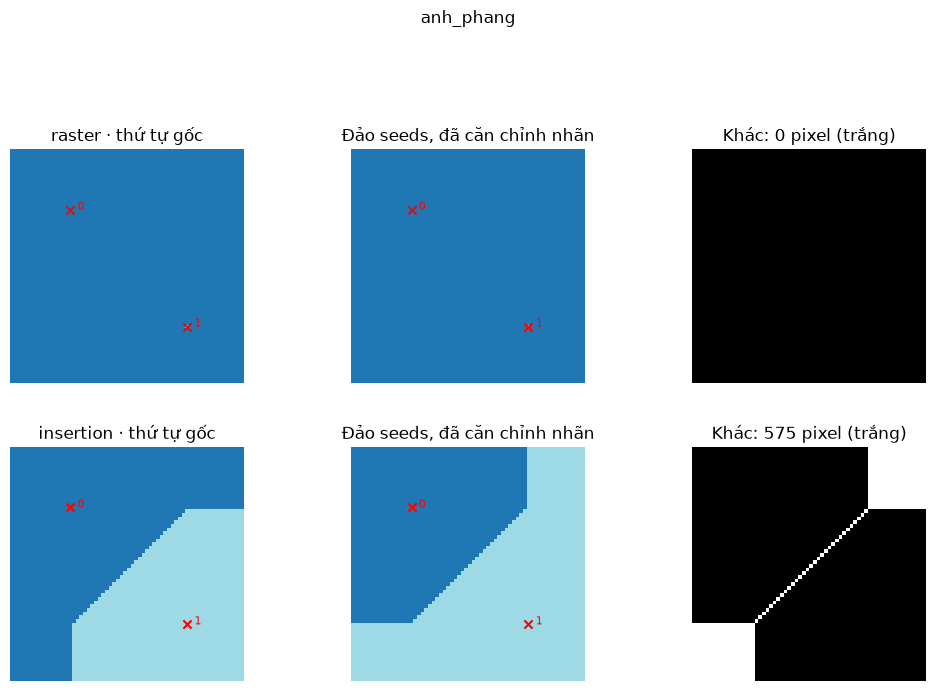

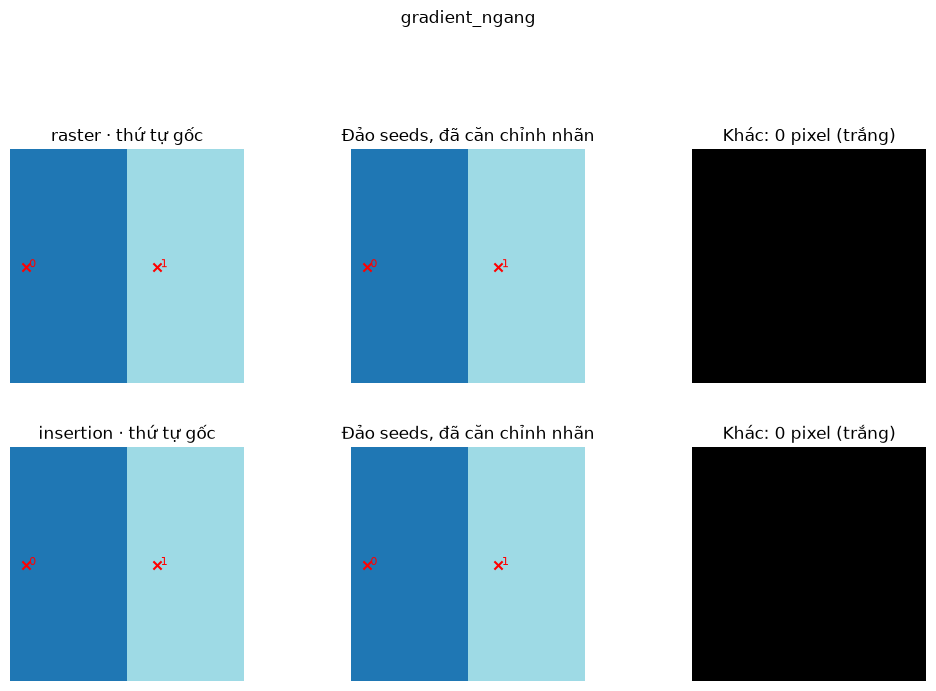

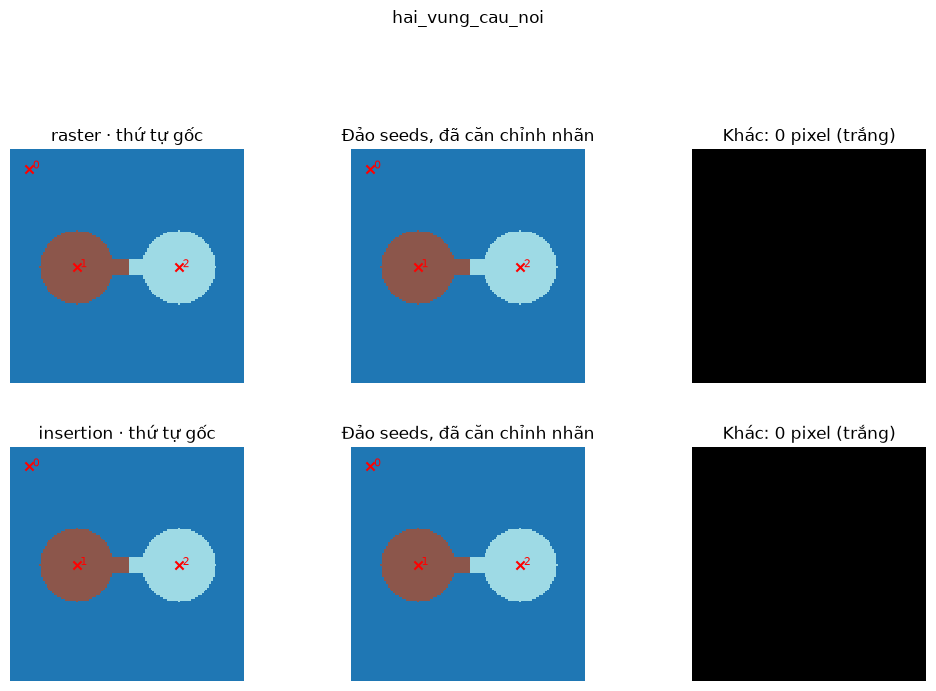

image            | tie       | different_pixels | total_pixels | different_fraction
anh_phang        | raster    | 0                | 4096         | 0.0               
anh_phang        | insertion | 575              | 4096         | 0.140380859375    
gradient_ngang   | raster    | 0                | 16384        | 0.0               
gradient_ngang   | insertion | 0                | 16384        | 0.0               
hai_vung_cau_noi | raster    | 0                | 16384        | 0.0               
hai_vung_cau_noi | insertion | 0                | 16384        | 0.0               
Đã lưu: ..\experiments\results\phan_b\synthetic\05_03_seed_order.csv

raster đạt bất biến sau căn chỉnh trên các ảnh đã chạy. insertion có thể đổi vùng khi hòa; bảng ghi cả kết quả bằng 0.


In [10]:
b_order_rows = []
for b_name, b_image in b_images.items():
    b_seeds = b_test_seeds[b_name]
    b_figure, b_axes = plt.subplots(2, 3, figsize=(11, 7))
    for b_tie, b_axis_row in zip(("raster", "insertion"), b_axes):
        b_original = (b_base[b_name][0] if b_tie == "insertion" else
                      srg(b_image, b_seeds, tie=b_tie)[0])
        b_reversed = srg(b_image, b_seeds[::-1], tie=b_tie)[0]
        b_aligned = b_align_labels(b_reversed, b_seeds)
        b_diff = b_align_labels(b_original, b_seeds) != b_aligned
        b_count = int(b_diff.sum())
        b_order_rows.append([b_name, b_tie, b_count, b_image.size, b_count / b_image.size])
        if b_tie == "raster":
            assert b_count == 0, f"Đảo seeds không bất biến trên ảnh {b_name} với raster"
        b_show_labels(b_axis_row[0], b_original, b_seeds, f"{b_tie} · thứ tự gốc")
        b_show_labels(b_axis_row[1], b_aligned, b_seeds, "Đảo seeds, đã căn chỉnh nhãn")
        b_axis_row[2].imshow(b_diff, cmap="gray", vmin=0, vmax=1)
        b_axis_row[2].set_title(f"Khác: {b_count} pixel (trắng)")
        b_axis_row[2].set_axis_off()
    b_figure.suptitle(b_name)
    b_figure.tight_layout()
    b_save_figure(b_figure, b_result_dir / f"05_03_order_{b_name}.png")
b_write_table(b_result_dir / "05_03_seed_order.csv",
              ["image", "tie", "different_pixels", "total_pixels", "different_fraction"], b_order_rows)
print("raster đạt bất biến sau căn chỉnh trên các ảnh đã chạy. insertion có thể đổi vùng khi hòa; bảng ghi cả kết quả bằng 0.")


**Nhận xét kiểm chứng — lần chạy 2026-11-14T22:32:12+07:00:**

Sau căn chỉnh, raster có 0 pixel khác trên cả ba ảnh. Với insertion: anh_phang: 575 pixel khác; gradient_ngang: 0 pixel khác; hai_vung_cau_noi: 0 pixel khác. Trường hợp ảnh phẳng cho thấy ties/thứ tự chèn có thể phá bất biến; không kết luận SRG luôn bất biến với mọi quy tắc.

Số đo/cấu hình đầy đủ trong bảng CSV và output phía trên; người thực hiện theo README.

### 5.4. Stack / queue / SRG

Cùng ảnh, seeds và miền [0,255]; Region Growing T=30, SRG lazy/insertion, connectivity 4. So từng cặp sau căn chỉnh nhãn, không loại pixel −1. [Bảng tổng hợp](../experiments/results/phan_b/synthetic/05_04_all_pairwise.csv).


**Khai báo AI — khung chạy kiểm chứng, hiển thị và lưu số đo.**

Prompt nguyên văn:

> chạy kiểm thử đi với thêm cell để chuẩn bị chạy ảnh thật (2 ảnh)

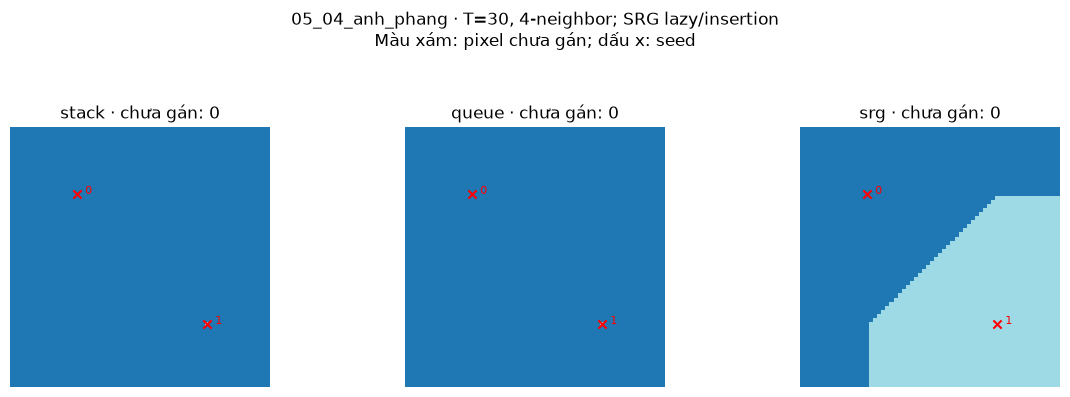

image           | method | T            | unassigned_pixels | assigned_fraction | seeds
05_04_anh_phang | stack  | 30.0         | 0                 | 1.0               | 2    
05_04_anh_phang | queue  | 30.0         | 0                 | 1.0               | 2    
05_04_anh_phang | srg    | không dùng T | 0                 | 1.0               | 2    
Đã lưu: ..\experiments\results\phan_b\synthetic\05_04_anh_phang_coverage.csv

image           | method_a | method_b | different_pixels | total_pixels | different_fraction
05_04_anh_phang | stack    | queue    | 0                | 4096         | 0.0               
05_04_anh_phang | stack    | srg      | 1712             | 4096         | 0.41796875        
05_04_anh_phang | queue    | srg      | 1712             | 4096         | 0.41796875        
Đã lưu: ..\experiments\results\phan_b\synthetic\05_04_anh_phang_pairwise.csv



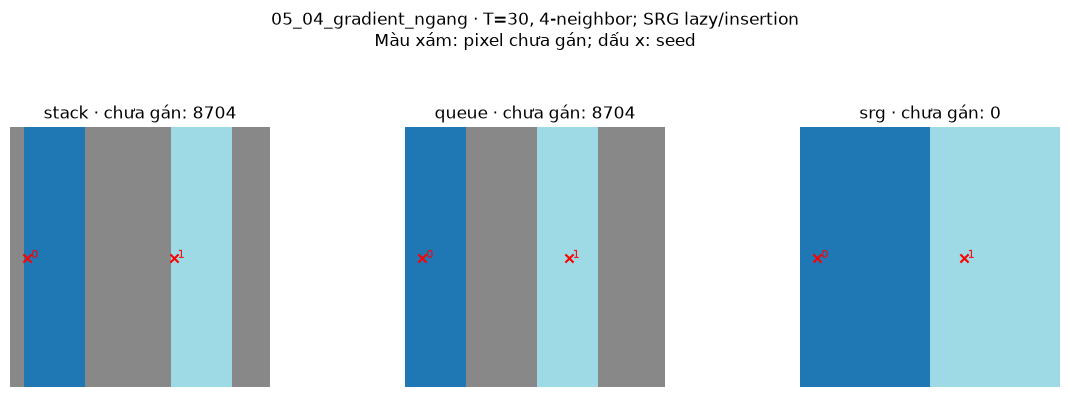

image                | method | T            | unassigned_pixels | assigned_fraction | seeds
05_04_gradient_ngang | stack  | 30.0         | 8704              | 0.46875           | 2    
05_04_gradient_ngang | queue  | 30.0         | 8704              | 0.46875           | 2    
05_04_gradient_ngang | srg    | không dùng T | 0                 | 1.0               | 2    
Đã lưu: ..\experiments\results\phan_b\synthetic\05_04_gradient_ngang_coverage.csv

image                | method_a | method_b | different_pixels | total_pixels | different_fraction
05_04_gradient_ngang | stack    | queue    | 5376             | 16384        | 0.328125          
05_04_gradient_ngang | stack    | srg      | 8704             | 16384        | 0.53125           
05_04_gradient_ngang | queue    | srg      | 8704             | 16384        | 0.53125           
Đã lưu: ..\experiments\results\phan_b\synthetic\05_04_gradient_ngang_pairwise.csv



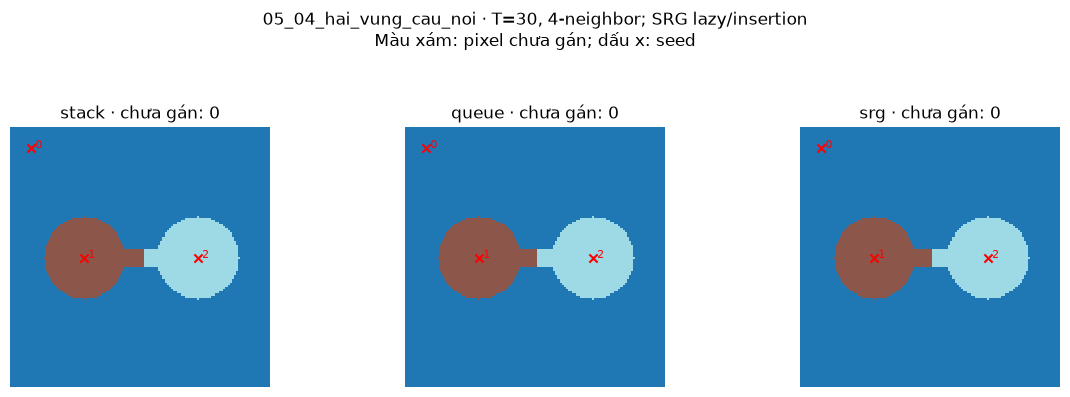

image                  | method | T            | unassigned_pixels | assigned_fraction | seeds
05_04_hai_vung_cau_noi | stack  | 30.0         | 0                 | 1.0               | 3    
05_04_hai_vung_cau_noi | queue  | 30.0         | 0                 | 1.0               | 3    
05_04_hai_vung_cau_noi | srg    | không dùng T | 0                 | 1.0               | 3    
Đã lưu: ..\experiments\results\phan_b\synthetic\05_04_hai_vung_cau_noi_coverage.csv

image                  | method_a | method_b | different_pixels | total_pixels | different_fraction
05_04_hai_vung_cau_noi | stack    | queue    | 9                | 16384        | 0.00054931640625  
05_04_hai_vung_cau_noi | stack    | srg      | 9                | 16384        | 0.00054931640625  
05_04_hai_vung_cau_noi | queue    | srg      | 0                | 16384        | 0.0               
Đã lưu: ..\experiments\results\phan_b\synthetic\05_04_hai_vung_cau_noi_pairwise.csv

image                  | method_a | method_b | dif

In [11]:
b_method_results = {}
b_pairwise_rows = []
for b_name, b_image in b_images.items():
    b_method_results[b_name] = b_compare_methods(
        b_image, b_test_seeds[b_name], b_test_T, b_result_dir,
        "05_04_" + b_name, srg_labels=b_base[b_name][0])
    b_pairwise_rows.extend(b_method_results[b_name]["pairwise"])
b_write_table(b_result_dir / "05_04_all_pairwise.csv",
              ["image", "method_a", "method_b", "different_pixels", "total_pixels", "different_fraction"], b_pairwise_rows)
print("Đếm trên toàn ảnh sau căn chỉnh nhãn; −1 được giữ là một trạng thái riêng, không bỏ khỏi mẫu số.")


**Nhận xét kiểm chứng — lần chạy 2026-11-14T22:32:12+07:00:**

Đã đo đủ chín phép so sánh (ba cặp × ba ảnh) với T=30. anh_phang stack/queue: 0 pixel; anh_phang stack/srg: 1712 pixel; anh_phang queue/srg: 1712 pixel; gradient_ngang stack/queue: 5376 pixel; gradient_ngang stack/srg: 8704 pixel; gradient_ngang queue/srg: 8704 pixel; hai_vung_cau_noi stack/queue: 9 pixel; hai_vung_cau_noi stack/srg: 9 pixel; hai_vung_cau_noi queue/srg: 0 pixel. Pixel −1 vẫn tham gia phép đếm; số bằng 0 là kết quả thực, không bị loại khỏi bảng.

Số đo/cấu hình đầy đủ trong bảng CSV và output phía trên; người thực hiện theo README.

### 5.5. Ảnh phẳng với hai seeds

So insertion/raster/random trên ảnh hằng 64×64, seeds (16,16), (48,48), RNG seed 42. Mọi delta bằng 0; đo ảnh hưởng riêng của phá hòa. [Bảng CSV](../experiments/results/phan_b/synthetic/05_05_ties.csv).


**Khai báo AI — khung chạy kiểm chứng, hiển thị và lưu số đo.**

Prompt nguyên văn:

> chạy kiểm thử đi với thêm cell để chuẩn bị chạy ảnh thật (2 ảnh)

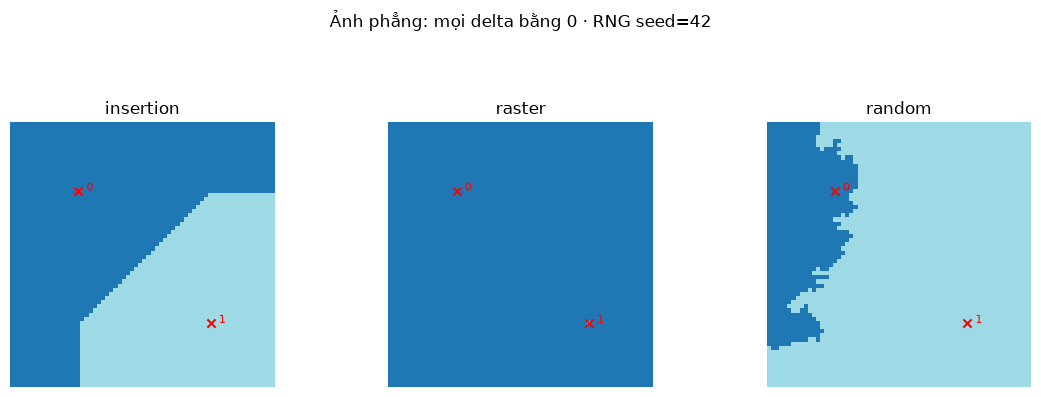

image     | tie_a     | tie_b  | rng_seed | different_pixels | total_pixels | different_fraction
anh_phang | insertion | raster | 42       | 1712             | 4096         | 0.41796875        
anh_phang | insertion | random | 42       | 1528             | 4096         | 0.373046875       
anh_phang | raster    | random | 42       | 3240             | 4096         | 0.791015625       
Đã lưu: ..\experiments\results\phan_b\synthetic\05_05_ties.csv



In [12]:
b_flat_labels = {"insertion": b_base["anh_phang"][0]}
for b_tie in ("raster", "random"):
    np.random.seed(b_rng_seed)
    b_flat_labels[b_tie] = srg(b_flat, b_test_seeds["anh_phang"], tie=b_tie)[0]
b_figure, b_axes = plt.subplots(1, 3, figsize=(12, 4))
for b_axis, (b_tie, b_labels) in zip(b_axes, b_flat_labels.items()):
    b_show_labels(b_axis, b_labels, b_test_seeds["anh_phang"], b_tie)
b_figure.suptitle(f"Ảnh phẳng: mọi delta bằng 0 · RNG seed={b_rng_seed}")
b_figure.tight_layout()
b_save_figure(b_figure, b_result_dir / "05_05_ties.png")
b_tie_rows = []
for b_first, b_second in [("insertion", "raster"), ("insertion", "random"), ("raster", "random")]:
    b_count = int(np.count_nonzero(b_flat_labels[b_first] != b_flat_labels[b_second]))
    b_tie_rows.append(["anh_phang", b_first, b_second, b_rng_seed, b_count, b_flat.size, b_count / b_flat.size])
assert any(row[4] > 0 for row in b_tie_rows)
b_write_table(b_result_dir / "05_05_ties.csv",
              ["image", "tie_a", "tie_b", "rng_seed", "different_pixels", "total_pixels", "different_fraction"], b_tie_rows)


**Nhận xét kiểm chứng — lần chạy 2026-11-14T22:32:12+07:00:**

Trên ảnh phẳng, insertion/raster: 1712 pixel khác; insertion/random: 1528 pixel khác; raster/random: 3240 pixel khác. Vì mọi delta bằng 0, thứ tự ưu tiên quyết định thứ tự kết nạp và khả năng tiếp cận các vùng. random được cố định seed 42.

Số đo/cấu hình đầy đủ trong bảng CSV và output phía trên; người thực hiện theo README.

### 5.6. Frames và độ nhạy seeds

Ảnh cầu nối, ba seeds đã khai báo. Chụp tám mốc 12,5%…100%; xác nhận frame độc lập và frame cuối khớp SRG. Sensitivity: 20 trial, jitter=3, seed 42, connectivity 4, lazy/insertion; tần suất đổi nhãn so với gốc sau căn chỉnh seed. Seeds dịch không trùng, trong ảnh theo docstring. Lưu [mốc frames](../experiments/results/phan_b/synthetic/05_06_frames.csv), [bảng sensitivity](../experiments/results/phan_b/synthetic/05_06_sensitivity_summary.csv) và bản đồ số thực NPY.


**Khai báo AI — khung chạy kiểm chứng, hiển thị và lưu số đo.**

Prompt nguyên văn:

> chạy kiểm thử đi với thêm cell để chuẩn bị chạy ảnh thật (2 ảnh)

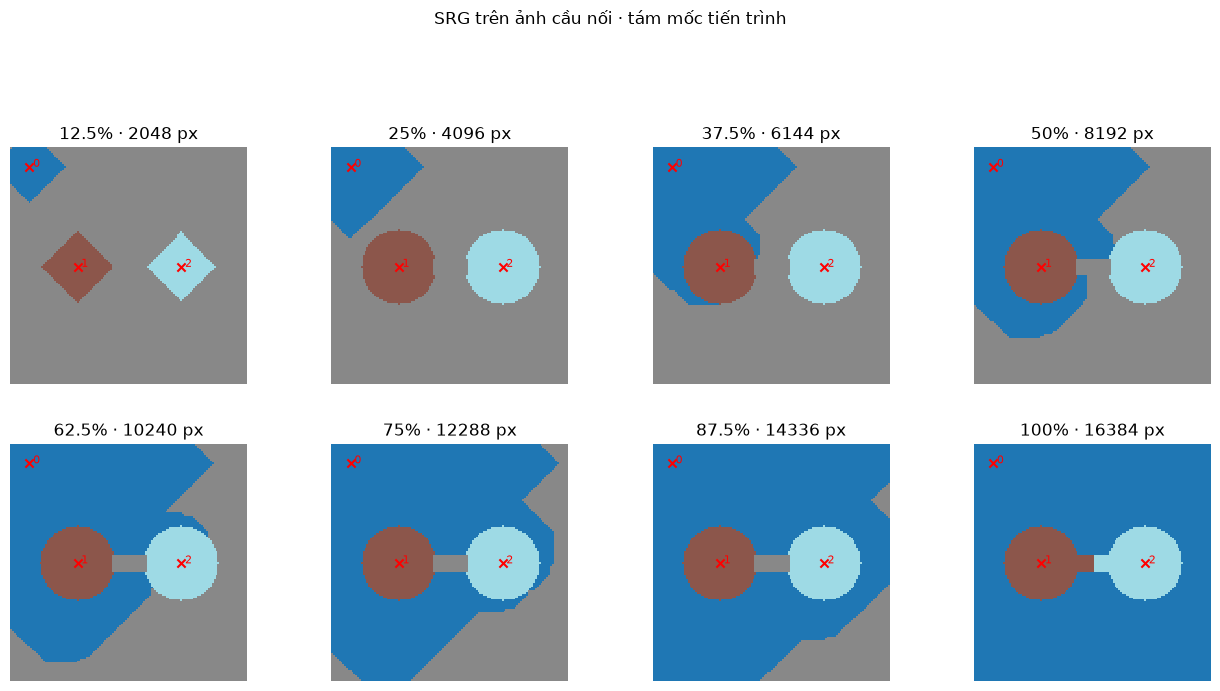

frame | target_percent | target_pixels | assigned_pixels | total_pixels
1     | 12.5           | 2048          | 2048            | 16384       
2     | 25.0           | 4096          | 4096            | 16384       
3     | 37.5           | 6144          | 6144            | 16384       
4     | 50.0           | 8192          | 8192            | 16384       
5     | 62.5           | 10240         | 10240           | 16384       
6     | 75.0           | 12288         | 12288           | 16384       
7     | 87.5           | 14336         | 14336           | 16384       
8     | 100.0          | 16384         | 16384           | 16384       
Đã lưu: ..\experiments\results\phan_b\synthetic\05_06_frames.csv



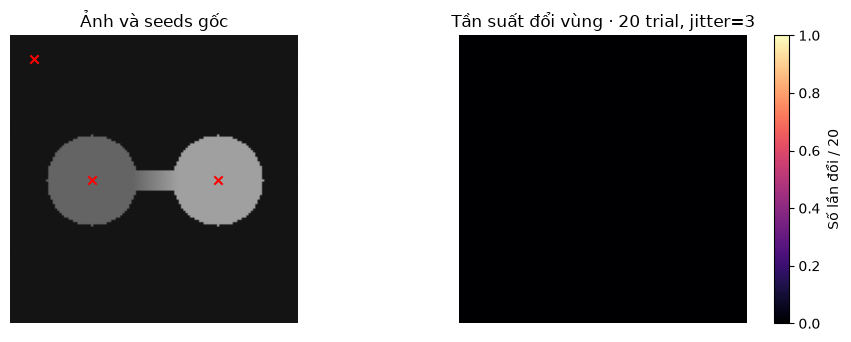

image            | trials | jitter | rng_seed | min_frequency | max_frequency | mean_frequency | nonzero_pixels
hai_vung_cau_noi | 20     | 3      | 42       | 0.0           | 0.0           | 0.0            | 0             
Đã lưu: ..\experiments\results\phan_b\synthetic\05_06_sensitivity_summary.csv

SRG lazy/insertion, connectivity=4. Tần suất so với phân vùng gốc sau căn chỉnh theo seed; 0 là ổn định trên các trial đã chạy.


In [13]:
b_frame_seeds = b_test_seeds["hai_vung_cau_noi"]
np.random.seed(b_rng_seed)
b_frames = srg_step_frames(b_bridge, b_frame_seeds, n_frames=8, connectivity=4, stale="lazy", tie="insertion")
assert len(b_frames) == 8
assert all(not np.shares_memory(first, second) for i, first in enumerate(b_frames) for second in b_frames[i + 1:])
assert np.array_equal(b_frames[-1], b_base["hai_vung_cau_noi"][0])
b_figure, b_axes = plt.subplots(2, 4, figsize=(13, 7))
b_frame_rows = []
for b_index, (b_axis, b_frame) in enumerate(zip(b_axes.flat, b_frames), 1):
    b_target = int(np.ceil(b_index * b_bridge.size / 8))
    b_assigned = int(np.count_nonzero(b_frame >= 0))
    assert b_assigned == b_target
    b_show_labels(b_axis, b_frame, b_frame_seeds, f"{100 * b_index / 8:g}% · {b_assigned} px")
    b_frame_rows.append([b_index, 100 * b_index / 8, b_target, b_assigned, b_bridge.size])
b_figure.suptitle("SRG trên ảnh cầu nối · tám mốc tiến trình")
b_figure.tight_layout()
b_save_figure(b_figure, b_result_dir / "05_06_frames.png")
b_write_table(b_result_dir / "05_06_frames.csv",
              ["frame", "target_percent", "target_pixels", "assigned_pixels", "total_pixels"], b_frame_rows)

np.random.seed(b_rng_seed)
b_sensitivity = seed_sensitivity(b_bridge, b_frame_seeds, srg, n_trials=20, jitter=3)
assert b_sensitivity.shape == b_bridge.shape and np.all((b_sensitivity >= 0) & (b_sensitivity <= 1))
np.save(b_result_dir / "05_06_sensitivity.npy", b_sensitivity)
b_figure, b_axes = plt.subplots(1, 2, figsize=(10, 4))
b_axes[0].imshow(b_bridge, cmap="gray", vmin=0, vmax=255)
b_axes[0].scatter(b_frame_seeds[:, 1], b_frame_seeds[:, 0], c="red", marker="x")
b_axes[0].set_title("Ảnh và seeds gốc")
b_heatmap = b_axes[1].imshow(b_sensitivity, cmap="magma", vmin=0, vmax=1)
b_axes[1].set_title("Tần suất đổi vùng · 20 trial, jitter=3")
for b_axis in b_axes:
    b_axis.set_axis_off()
b_figure.colorbar(b_heatmap, ax=b_axes[1], label="Số lần đổi / 20")
b_figure.tight_layout()
b_save_figure(b_figure, b_result_dir / "05_06_sensitivity.png")
b_write_table(b_result_dir / "05_06_sensitivity_summary.csv",
              ["image", "trials", "jitter", "rng_seed", "min_frequency", "max_frequency", "mean_frequency", "nonzero_pixels"],
              [["hai_vung_cau_noi", 20, 3, b_rng_seed, float(b_sensitivity.min()),
                float(b_sensitivity.max()), float(b_sensitivity.mean()), int(np.count_nonzero(b_sensitivity))]])
print("SRG lazy/insertion, connectivity=4. Tần suất so với phân vùng gốc sau căn chỉnh theo seed; 0 là ổn định trên các trial đã chạy.")


**Nhận xét kiểm chứng — lần chạy 2026-11-14T22:32:12+07:00:**

Tám frame là các bản sao độc lập, số pixel đã gán lần lượt 2048, 4096, 6144, 8192, 10240, 12288, 14336, 16384; frame cuối khớp SRG. Sensitivity trên ảnh cầu nối với 20 trial, jitter=3 có 0 pixel thay đổi, trung bình 0.000000, cực đại 0.000000. Trong cấu hình này seeds nằm sâu trong các vùng đồng nhất và các dịch chuyển đã thử không làm đổi phân vùng; không suy ra mọi ảnh hoặc mọi jitter đều ổn định.

Số đo/cấu hình đầy đủ trong bảng CSV và output phía trên; người thực hiện theo README.

## 6. Thí nghiệm — SRG so với Region Growing

Giữ cùng ảnh và seeds; ghi ngưỡng T cho Region Growing, cách căn chỉnh nhãn và pixel chưa được gán.

### Phiếu thiết kế — nhóm quyết định trước khi chạy

| Trường | Nội dung do nhóm tự điền |
| --- | --- |
| Câu hỏi và giả thuyết | Chưa điền |
| Ảnh, nguồn, lý do chọn và chỉnh sửa | Chưa chọn |
| Biến độc lập và tập giá trị quét | Chưa chọn |
| Yếu tố giữ cố định | Chưa điền |
| Phép đo, định nghĩa, đơn vị và mẫu số | Chưa chọn |
| Seed ngẫu nhiên, số lần lặp, cách tổng hợp | Chưa chọn |
| Bằng chứng cần lưu: ảnh, bảng, đường cong | Chưa điền |

### Kết quả — chỉ điền số đo thật

**Ngữ cảnh 5W1H — điền khi có kết quả thực:**
- What: đại lượng, đơn vị, ý nghĩa — chưa điền.
- Why: câu hỏi cần trả lời — chưa điền.
- When: thời điểm, lần chạy, seed — chưa điền.
- Where: ảnh, thiết bị và đường dẫn artifact — chưa điền.
- Who: người thực hiện và cấu hình thuật toán — chưa điền.
- How: tham số, cách tính, số lần lặp và tổng hợp — chưa điền.


| Lần chạy | Giá trị tham số quét | Cấu hình cố định | Phương pháp | Đại lượng / đơn vị | Giá trị | Artifact |
| --- | --- | --- | --- | --- | --- | --- |
| Chưa chạy | Chưa chọn | Chưa ghi | Chưa ghi | Chưa chọn | Chưa đo | Chưa có |

Ô dưới để bổ sung khung chạy / vẽ sau khi nhóm chốt thiết kế.


### Phân tích và giới hạn — nhóm tự viết

- Bằng chứng khác biệt giữa hai phương pháp: chưa có.
- Đường cong / điểm chuyển hành vi khi quét tham số: chưa có.
- Đại lượng nào thay đổi, tại bước nào, vì sao gây ra hiện tượng: chưa phân tích.
- Kết quả có khớp giả thuyết không, phạm vi áp dụng và giới hạn: chưa kết luận.

- [ ] Có ít nhất một phép đo và bảng số gốc.
- [ ] Có đường cong quét tham số, tên trục, đơn vị và chú giải.
- [ ] Giải thích cơ chế thay vì chỉ nói phương pháp nào tốt hơn.


### 6.1. So sánh lazy / frozen

Ảnh gradient 128×128, seeds (64,8), (64,80). Giữ connectivity 4, tie insertion; chỉ đổi stale. Đếm pixel khác/tổng pixel, minh họa giá trị tham chiếu trung bình vùng so với cường độ seed. [Bảng CSV](../experiments/results/phan_b/synthetic/06_01_lazy_frozen.csv).


**Khai báo AI — khung chạy kiểm chứng, hiển thị và lưu số đo.**

Prompt nguyên văn:

> chạy kiểm thử đi với thêm cell để chuẩn bị chạy ảnh thật (2 ảnh)

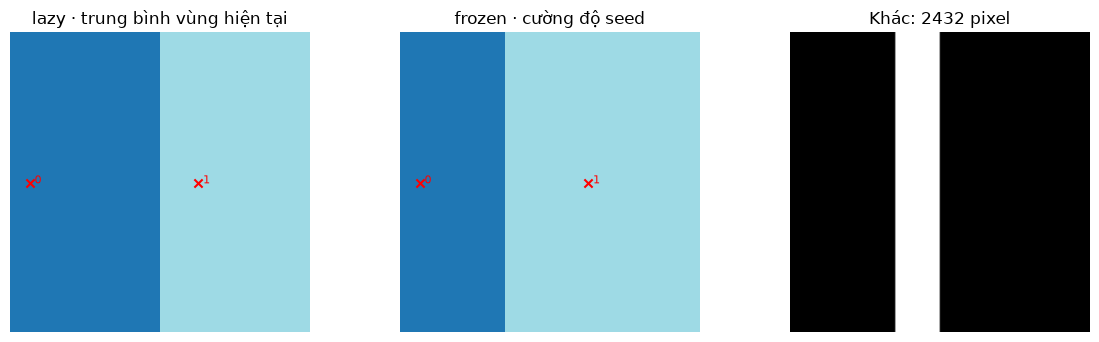

image          | connectivity | tie       | different_pixels | total_pixels | different_fraction
gradient_ngang | 4            | insertion | 2432             | 16384        | 0.1484375         
Đã lưu: ..\experiments\results\phan_b\synthetic\06_01_lazy_frozen.csv

Chỉ đổi stale. lazy cập nhật giá trị tham chiếu theo vùng; frozen giữ cường độ tại seed, nên vị trí ranh giới trên gradient có thể khác.


In [14]:
b_lazy = b_base["gradient_ngang"][0]
b_frozen = srg(b_gradient, b_test_seeds["gradient_ngang"], connectivity=4, stale="frozen", tie="insertion")[0]
b_stale_count = int(np.count_nonzero(b_lazy != b_frozen))
b_figure, b_axes = plt.subplots(1, 3, figsize=(12, 4))
b_show_labels(b_axes[0], b_lazy, b_test_seeds["gradient_ngang"], "lazy · trung bình vùng hiện tại")
b_show_labels(b_axes[1], b_frozen, b_test_seeds["gradient_ngang"], "frozen · cường độ seed")
b_axes[2].imshow(b_lazy != b_frozen, cmap="gray", vmin=0, vmax=1)
b_axes[2].set_title(f"Khác: {b_stale_count} pixel")
b_axes[2].set_axis_off()
b_figure.tight_layout()
b_save_figure(b_figure, b_result_dir / "06_01_lazy_frozen.png")
b_write_table(b_result_dir / "06_01_lazy_frozen.csv",
              ["image", "connectivity", "tie", "different_pixels", "total_pixels", "different_fraction"],
              [["gradient_ngang", 4, "insertion", b_stale_count, b_gradient.size, b_stale_count / b_gradient.size]])
print("Chỉ đổi stale. lazy cập nhật giá trị tham chiếu theo vùng; frozen giữ cường độ tại seed, nên vị trí ranh giới trên gradient có thể khác.")


**Nhận xét kiểm chứng — lần chạy 2026-11-14T22:32:12+07:00:**

lazy/frozen khác 2432/16384 pixel (14.8438%) trên gradient. Hai cấu hình chỉ khác giá trị tham chiếu delta: lazy thích nghi với trung bình vùng, frozen giữ giá trị tại seed; điều này làm đổi ranh giới trên gradient đã chạy.

Số đo/cấu hình đầy đủ trong bảng CSV và output phía trên; người thực hiện theo README.

### 6.2. Ảnh hưởng phá hòa

Dùng lại đúng kết quả ảnh phẳng ở mục 5.5 để tránh thay cấu hình. Các vùng có thể khác dù mọi delta bằng 0; random được cố định seed 42. [Bảng CSV](../experiments/results/phan_b/synthetic/06_02_ties.csv).


**Khai báo AI — khung chạy kiểm chứng, hiển thị và lưu số đo.**

Prompt nguyên văn:

> chạy kiểm thử đi với thêm cell để chuẩn bị chạy ảnh thật (2 ảnh)

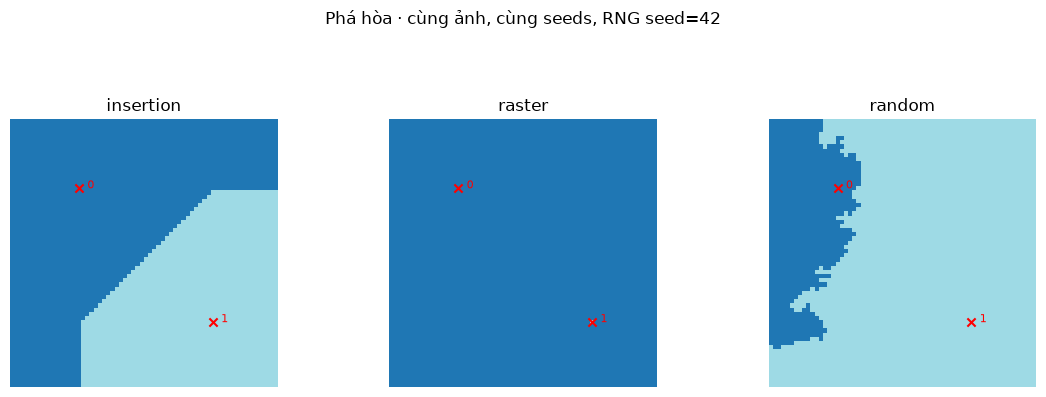

image     | tie_a     | tie_b  | rng_seed | different_pixels | total_pixels | different_fraction
anh_phang | insertion | raster | 42       | 1712             | 4096         | 0.41796875        
anh_phang | insertion | random | 42       | 1528             | 4096         | 0.373046875       
anh_phang | raster    | random | 42       | 3240             | 4096         | 0.791015625       
Đã lưu: ..\experiments\results\phan_b\synthetic\06_02_ties.csv

Ảnh phẳng có mọi delta bằng nhau: thứ tự ưu tiên quyết định pixel nào được gán trước, từ đó đổi khả năng tiếp cận các vùng.


In [15]:
# Dùng lại đúng kết quả ảnh phẳng ở mục 5.5; không chạy một cấu hình khác ngầm.
b_figure, b_axes = plt.subplots(1, 3, figsize=(12, 4))
for b_axis, (b_tie, b_labels) in zip(b_axes, b_flat_labels.items()):
    b_show_labels(b_axis, b_labels, b_test_seeds["anh_phang"], b_tie)
b_figure.suptitle(f"Phá hòa · cùng ảnh, cùng seeds, RNG seed={b_rng_seed}")
b_figure.tight_layout()
b_save_figure(b_figure, b_result_dir / "06_02_ties.png")
b_write_table(b_result_dir / "06_02_ties.csv",
              ["image", "tie_a", "tie_b", "rng_seed", "different_pixels", "total_pixels", "different_fraction"], b_tie_rows)
print("Ảnh phẳng có mọi delta bằng nhau: thứ tự ưu tiên quyết định pixel nào được gán trước, từ đó đổi khả năng tiếp cận các vùng.")


**Nhận xét kiểm chứng — lần chạy 2026-11-14T22:32:12+07:00:**

Bằng chứng từ ảnh phẳng được dùng lại nhất quán với mục 5.5: insertion/raster: 1712 pixel; insertion/random: 1528 pixel; raster/random: 3240 pixel. Đây là một ảnh xác nhận thay phá hòa làm đổi kết quả; không phải tuyên bố một quy tắc tốt hơn trên mọi ảnh.

Số đo/cấu hình đầy đủ trong bảng CSV và output phía trên; người thực hiện theo README.

## 7. Chuẩn bị chạy hai ảnh thật

Chưa có ảnh thật trong thư mục ảnh B; hai ô cấu hình mặc định để trống, không lấy ảnh tổng hợp thay thế.

1. Đặt hai ảnh của nhóm vào [images/phan_b](../images/phan_b/), điền tên file ở `path` (ví dụ `anh_that_01.jpg`) và nguồn/quyền sử dụng ở `source`.
2. Chạy cell để xem ảnh xám, kích thước gốc/làm việc và trục tọa độ. Cạnh dài được giới hạn 256 pixel, giữ tỷ lệ; không phóng to ảnh nhỏ.
3. Điền seeds theo **ảnh làm việc sau resize**, theo `(row, col)`, không trùng và nằm trong ảnh. Điều chỉnh `T` theo miền `[0,255]`.
4. Chạy lại để so stack/queue/SRG (connectivity 4, lazy/insertion, RNG seed 42). Màu xám trong ảnh nhãn biểu thị pixel chưa gán; bảng pixel khác giữ trạng thái này trong mẫu số.

Thiếu file hoặc seeds thì hiển thị thông báo và bỏ qua slot đó. Khi đủ cấu hình, hình, bảng so sánh và nguồn/cấu hình được lưu tại [kết quả ảnh thật](../experiments/results/phan_b/real/). Chưa có ảnh thật thì không công bố kết quả ảnh thật. Các hàm OpenCV chỉ dùng để nạp ảnh xám và resize, ngoài phần cài đặt thuật toán.

**Khai báo AI — chuẩn bị nạp hai ảnh thật, kiểm tra seeds và chạy so sánh.**

Prompt nguyên văn:

> chạy kiểm thử đi với thêm cell để chuẩn bị chạy ảnh thật (2 ảnh)

In [16]:
def b_run_real_images(cases, max_side=256, image_dir=None, output_dir=None):
    """Nạp các ô ảnh thật; chỉ chạy khi đủ ảnh và seeds sau resize.

    Không dùng ảnh tổng hợp thay ảnh thật khi thiếu cấu hình. Trả trạng thái
    từng ô để phân biệt chưa cấu hình, lỗi dữ liệu và chạy hoàn tất.
    """
    max_side = _b_integer(max_side, "max_side", 1)
    image_dir = Path("../images/phan_b") if image_dir is None else Path(image_dir)
    output_dir = Path("../experiments/results/phan_b/real") if output_dir is None else Path(output_dir)
    reports, completed = [], []
    for case in cases:
        name = case["name"]
        report = {"name": name}
        configured = case.get("path")
        if not configured:
            report["status"] = "missing_image"
            print(f"{name}: chưa cấu hình ảnh — bỏ qua.")
            reports.append(report)
            continue
        path = Path(configured)
        if not path.is_absolute():
            path = image_dir / path
        if not path.is_file():
            report["status"] = "missing_image"
            print(f"{name}: không tìm thấy {path} — bỏ qua.")
            reports.append(report)
            continue
        image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
        if image is None:
            report["status"] = "unreadable_image"
            print(f"{name}: không đọc được ảnh {path} — bỏ qua.")
            reports.append(report)
            continue
        original_shape = image.shape
        scale = min(1.0, max_side / max(original_shape))
        if scale < 1:
            size = (max(1, round(original_shape[1] * scale)), max(1, round(original_shape[0] * scale)))
            image = cv2.resize(image, size, interpolation=cv2.INTER_AREA)
        report.update(image=image, original_shape=original_shape, working_shape=image.shape)
        figure, axis = plt.subplots(figsize=(7, 5))
        axis.imshow(image, cmap="gray", vmin=0, vmax=255)
        axis.set_title(f"{name} · gốc {original_shape}, làm việc {image.shape}")
        axis.set_xlabel("col — nhập seeds theo ảnh làm việc này")
        axis.set_ylabel("row")
        seeds = case.get("seeds", [])
        if len(seeds) == 0:
            report["status"] = "missing_seeds"
            print(f"{name}: đã nạp ảnh nhưng chưa có seeds — chỉ xem trước, chưa phân vùng.")
            plt.show()
            plt.close(figure)
            reports.append(report)
            continue
        try:
            _, seeds = _b_inputs(image, seeds)
        except ValueError as error:
            report["status"] = "invalid_seeds"
            print(f"{name}: {error} — sửa seeds theo tọa độ ảnh làm việc rồi chạy lại.")
            plt.show()
            plt.close(figure)
            reports.append(report)
            continue
        axis.scatter(seeds[:, 1], seeds[:, 0], c="red", marker="x")
        for region, (row, col) in enumerate(seeds):
            axis.text(col + 2, row, str(region), color="red")
        b_save_figure(figure, output_dir / f"{name}_input.png")
        result = b_compare_methods(image, seeds, case.get("T", 30.0), output_dir, name)
        report.update(status="completed", result=result)
        completed.append([name, str(path), case.get("source", ""), str(original_shape), str(image.shape),
                          seeds.tolist(), case.get("T", 30.0), b_rng_seed, b_run_stamp])
        reports.append(report)
        if not case.get("source"):
            print(f"{name}: hãy bổ sung nguồn ảnh vào ô source.")
    if completed:
        b_write_table(output_dir / "metadata.csv",
                      ["image", "path", "source", "original_shape", "working_shape", "seeds_row_col", "T", "rng_seed", "run_at"], completed)
    return reports


**Khai báo AI — hai ô cấu hình ảnh thật, chưa có dữ liệu thì bỏ qua.**

Prompt nguyên văn:

> chạy kiểm thử đi với thêm cell để chuẩn bị chạy ảnh thật (2 ảnh)

In [17]:
# Đường dẫn tương đối được tính từ ../images/phan_b/; chưa có ảnh thì để None.
# Bước 1: điền path/source và chạy để xem tọa độ ảnh sau resize.
# Bước 2: điền seeds (row, col) theo ảnh làm việc rồi chạy lại.
b_real_cases = [
    {"name": "anh_that_01", "path": None, "source": "", "seeds": [], "T": 30.0},
    {"name": "anh_that_02", "path": None, "source": "", "seeds": [], "T": 30.0},
]
b_real_max_side = 256
b_real_reports = b_run_real_images(b_real_cases, max_side=b_real_max_side)
print("Trạng thái hai ô ảnh thật:", [(case["name"], case["status"]) for case in b_real_reports])


anh_that_01: chưa cấu hình ảnh — bỏ qua.
anh_that_02: chưa cấu hình ảnh — bỏ qua.
Trạng thái hai ô ảnh thật: [('anh_that_01', 'missing_image'), ('anh_that_02', 'missing_image')]


## Tổng kết và checklist phần B

- [x] Đủ bốn hàm B và các kiểm tra hồi quy thuật toán.
- [x] Đủ năm kiểm chứng bắt buộc có output; seed-order ghi riêng ảnh hưởng ties.
- [x] Có frames, sensitivity, lazy/frozen và bằng chứng ảnh hưởng phá hòa, đã chạy sạch và lưu output.
- [ ] Hoàn thành thí nghiệm chính: chốt giả thuyết, quét tham số, đường cong và phân tích. Mục 6 còn chờ nhóm thực hiện.
- [ ] Điền hai ảnh thật, nguồn và seeds; hiện chỉ có ô chuẩn bị, không phải kết quả ảnh thật.
- [ ] Ghép với A thành một notebook, sửa đường dẫn và chạy sạch trước khi nộp.

Kết quả tổng hợp chỉ chứng minh các trường hợp đã chạy. Chưa có phép quét tham số chính, chưa có kết luận về ảnh thật.
